<a href="https://colab.research.google.com/github/kibarp5/prediksi-gagal-bayar-kartu-kredit/blob/main/Prediksi_Gagal_Bayar_Kartu_Kredit_Menggunakan_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prediksi Gagal Bayar Kartu Kredit Menggunakan Machine Learning

**UTS Prediksi Modern & Machine Learning**

Nama: Kibar Panji Jatnika  
NIM: 2404220041  
Program studi: Statistika dan Sains Data



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay

# A. Data Understanding dan Preparation — Experiment 0

In [ ]:
df = pd.read_csv('UCI_Credit_Card.csv')
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [ ]:
print('Ukuran dataset:', df.shape)
df.info()

Ukuran dataset: (30000, 25)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BIL

In [ ]:
# Cek missing value
df.isna().sum()

,0
ID,0
LIMIT_BAL,0
SEX,0
EDUCATION,0
MARRIAGE,0
AGE,0
PAY_0,0
PAY_2,0
PAY_3,0
PAY_4,0


In [ ]:
print('Duplikat seluruh kolom:', df.duplicated().sum())
print('Duplikat tanpa ID:', df.drop(columns='ID').duplicated().sum())
print('Duplikat predictor:', df.drop(columns=['ID', 'default.payment.next.month']).duplicated().sum())

for kolom in ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']:
    print(kolom, df[kolom].value_counts().sort_index().to_dict())

Duplikat seluruh kolom: 0
Duplikat tanpa ID: 35
Duplikat predictor: 56
SEX {1: 11888, 2: 18112}
EDUCATION {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE {0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_0 {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}
PAY_2 {-2: 3782, -1: 6050, 0: 15730, 1: 28, 2: 3927, 3: 326, 4: 99, 5: 25, 6: 12, 7: 20, 8: 1}
PAY_3 {-2: 4085, -1: 5938, 0: 15764, 1: 4, 2: 3819, 3: 240, 4: 76, 5: 21, 6: 23, 7: 27, 8: 3}
PAY_4 {-2: 4348, -1: 5687, 0: 16455, 1: 2, 2: 3159, 3: 180, 4: 69, 5: 35, 6: 5, 7: 58, 8: 2}
PAY_5 {-2: 4546, -1: 5539, 0: 16947, 2: 2626, 3: 178, 4: 84, 5: 17, 6: 4, 7: 58, 8: 1}
PAY_6 {-2: 4895, -1: 5740, 0: 16286, 2: 2766, 3: 184, 4: 49, 5: 13, 6: 19, 7: 46, 8: 2}


In [ ]:
print('Jumlah tagihan negatif:', (df.filter(like='BILL_AMT') < 0).sum().sum())
print('Jumlah pembayaran negatif:', (df.filter(like='PAY_AMT') < 0).sum().sum())
df.drop(columns=['ID', 'default.payment.next.month']).agg(['min', 'max']).T

Jumlah tagihan negatif: 3932
Jumlah pembayaran negatif: 0


,min,max
LIMIT_BAL,10000.0,1000000.0
SEX,1.0,2.0
EDUCATION,0.0,6.0
MARRIAGE,0.0,3.0
AGE,21.0,79.0
PAY_0,-2.0,8.0
PAY_2,-2.0,8.0
PAY_3,-2.0,8.0
PAY_4,-2.0,8.0
PAY_5,-2.0,8.0


In [ ]:
pd.DataFrame({
    'Jumlah': df['default.payment.next.month'].value_counts(),
    'Persentase': df['default.payment.next.month'].value_counts(normalize=True) * 100
}).sort_index().round(2)

,Jumlah,Persentase
default.payment.next.month,,
0,23364,77.88
1,6636,22.12


Dataset berisi 30.000 baris dan 25 kolom tanpa missing value. Target
`default.payment.next.month` bernilai 0 untuk tidak gagal bayar dan 1 untuk gagal bayar
pada bulan berikutnya. Proporsi kelas gagal bayar sebesar 22,12%, sehingga evaluasi
mengutamakan F1 kelas 1 dan tetap melaporkan accuracy, precision, serta recall.

Ada 35 baris tambahan yang identik setelah ID dikeluarkan dan 56 baris tambahan dengan
seluruh predictor identik. Seluruh baris dipertahankan; profil identik ditempatkan dalam
kelompok yang sama saat pembagian data agar tidak tersebar ke training dan testing.

Kode EDUCATION 0/5/6, MARRIAGE 0, dan status pembayaran -2/0 tetap diperlakukan sebagai
kategori tanpa diberi arti baru. Tagihan negatif serta nilai nominal besar tidak dihapus
karena belum ada bukti bahwa nilai tersebut merupakan kesalahan pencatatan.

In [ ]:
X = df.drop(columns=['ID', 'default.payment.next.month'])
y = df['default.payment.next.month']

# Nasabah dengan predictor identik masuk kelompok yang sama.
grup = pd.factorize(pd.MultiIndex.from_frame(X))[0]
split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
idx_train, idx_test = next(split.split(X, y, grup))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]

print('Data training:', X_train.shape)
print('Data testing :', X_test.shape)
print('Proporsi gagal bayar training:', round(y_train.mean(), 4))
print('Proporsi gagal bayar testing :', round(y_test.mean(), 4))

Data training: (24004, 23)
Data testing : (5996, 23)
Proporsi gagal bayar training: 0.2216
Proporsi gagal bayar testing : 0.2195


In [ ]:
# Lima fold training ini dipakai untuk semua eksperimen.
skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
cv = list(skf.split(X_train, y_train, grup[idx_train]))

Data dibagi menjadi **24.004** baris training dan **5.996** baris testing.
StratifiedGroupKFold menjaga agar profil identik tidak masuk ke kedua bagian data.
Data training dibagi lagi menjadi lima fold yang sama untuk seluruh eksperimen.

Pemilihan model dan tuning menggunakan CV F1 pada data training. Data testing digunakan untuk evaluasi akhir setelah model final dipilih pada bagian G.

# B. Baseline Model — Experiment 1

Baseline menggunakan Logistic Regression dengan predictor mentah, tanpa scaling
dan encoding. ID sudah dikeluarkan dari predictor.

In [ ]:
baseline = LogisticRegression(C=1.0, solver='liblinear', max_iter=2000, random_state=42)

cv_baseline = cross_val_score(baseline, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)
baseline.fit(X_train, y_train)

print('Rata-rata CV F1:', round(cv_baseline.mean(), 4))
pd.DataFrame({'Fold': range(1, 6), 'F1': cv_baseline}).round(4)

Rata-rata CV F1: 0.0004


,Fold,F1
0,1,0.0019
1,2,0.0000
2,3,0.0000
3,4,0.0000
4,5,0.0000


# C. Baseline + Preprocessing — Experiment 2

Kolom numerik menggunakan StandardScaler, sedangkan kategori menggunakan
OneHotEncoder. Preprocessing dimasukkan ke pipeline supaya scaler dan encoder
hanya belajar dari data training pada setiap fold. Pengaturan Logistic Regression
dibuat sama dengan baseline.

In [ ]:
kolom_kategori = ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
kolom_numerik = [kolom for kolom in X.columns if kolom not in kolom_kategori]

preprocessing = ColumnTransformer([
    ('numerik', StandardScaler(), kolom_numerik),
    ('kategori', OneHotEncoder(handle_unknown='ignore', sparse_output=False), kolom_kategori)
])

lr = Pipeline([
    ('preprocessing', clone(preprocessing)),
    ('model', LogisticRegression(C=1.0, solver='liblinear', max_iter=2000, random_state=42))
])

In [ ]:
cv_lr = cross_val_score(lr, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)
lr.fit(X_train, y_train)

pd.DataFrame({
    'Model': ['Baseline', 'Baseline + Preprocessing'],
    'CV F1': [cv_baseline.mean(), cv_lr.mean()]
}).round(4)

,Model,CV F1
0,Baseline,0.0004
1,Baseline + Preprocessing,0.4646


Setelah preprocessing, rata-rata CV F1 berubah dari **0.0004** menjadi **0.4646**. Scaling dan encoding diterapkan bersama pada percobaan ini, sehingga pengaruh masing-masing teknik belum dapat dipisahkan dari hasil tersebut.

# D. Model Comparison — Experiment 3

Model yang dibandingkan adalah Logistic Regression, Decision Tree, dan Random Forest.
Ketiganya menggunakan preprocessing dan fold yang sama. Hasil Logistic Regression
diambil dari Experiment 2 karena konfigurasinya tidak berubah.

In [ ]:
dt = Pipeline([
    ('preprocessing', clone(preprocessing)),
    ('model', DecisionTreeClassifier(random_state=42))
])

rf = Pipeline([
    ('preprocessing', clone(preprocessing)),
    ('model', RandomForestClassifier(n_estimators=150, n_jobs=1, random_state=42))
])

cv_dt = cross_val_score(dt, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)
dt.fit(X_train, y_train)

cv_rf = cross_val_score(rf, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)
rf.fit(X_train, y_train)

perbandingan = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'CV F1': [cv_lr.mean(), cv_dt.mean(), cv_rf.mean()]
})
perbandingan.sort_values('CV F1', ascending=False).round(4)

,Model,CV F1
2,Random Forest,0.4697
0,Logistic Regression,0.4646
1,Decision Tree,0.3966


In [ ]:
nama_terbaik = perbandingan.loc[perbandingan['CV F1'].idxmax(), 'Model']
print('CV F1 tertinggi pada eksperimen 3:', nama_terbaik)
print('Model yang dituning pada eksperimen 4: Random Forest')

CV F1 tertinggi pada eksperimen 3: Random Forest
Model yang dituning pada eksperimen 4: Random Forest


Pada eksperimen 3, Random Forest memperoleh CV F1 tertinggi sebesar 0.4697. Logistic Regression memiliki CV F1 0.4646, Decision Tree 0.3966, dan Random Forest 0.4697.

Eksperimen berikutnya secara khusus melakukan tuning pada Random Forest untuk menilai pengaruh kedalaman pohon, ukuran minimum daun, dan bobot kelas terhadap kemampuan model mendeteksi gagal bayar. Selisih CV F1 antarmodel pada satu pembagian data belum menunjukkan bahwa suatu model selalu lebih baik pada data lain.

# E. Tuning Random Forest — Experiment 4

GridSearchCV diterapkan langsung pada pipeline Random Forest menggunakan lima fold
training yang sama dan F1 sebagai scoring. Pencarian mencakup 12 kombinasi parameter;
jumlah pohon tetap 150 seperti pada eksperimen 3. Seluruh proses tuning menggunakan
data training.

In [ ]:
param_grid = {
    'model__max_depth': [None, 8, 16],
    'model__min_samples_leaf': [1, 5],
    'model__class_weight': [None, 'balanced']
}
param_grid

{'model__max_depth': [None, 8, 16],
 'model__min_samples_leaf': [1, 5],
 'model__class_weight': [None, 'balanced']}

In [ ]:
grid_search = GridSearchCV(
    estimator=clone(rf),
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

print('Model yang dituning: Random Forest')
print('Parameter terbaik:', grid_search.best_params_)
print('Best CV F1:', round(grid_search.best_score_, 4))

hasil_tuning = pd.DataFrame(grid_search.cv_results_)
kolom_parameter = [kolom for kolom in hasil_tuning.columns if kolom.startswith('param_')]
hasil_tuning[kolom_parameter + ['mean_test_score', 'rank_test_score']].sort_values('rank_test_score').round(4)

Model yang dituning: Random Forest
Parameter terbaik: {'model__class_weight': 'balanced', 'model__max_depth': 16, 'model__min_samples_leaf': 5}
Best CV F1: 0.5453


,param_model__class_weight,param_model__max_depth,param_model__min_samples_leaf,mean_test_score,rank_test_score
11,balanced,16,5,0.5453,1
7,balanced,None,5,0.5427,2
9,balanced,8,5,0.5390,3
8,balanced,8,1,0.5374,4
10,balanced,16,1,0.5149,5
0,None,None,1,0.4697,6
4,None,16,1,0.4619,7
1,None,None,5,0.4591,8
5,None,16,5,0.4575,9
6,balanced,None,1,0.4534,10


In [ ]:
pd.DataFrame({
    'Model': ['Random Forest sebelum tuning', 'Random Forest setelah tuning'],
    'CV F1': [cv_rf.mean(), grid_search.best_score_]
}).round(4)

,Model,CV F1
0,Random Forest sebelum tuning,0.4697
1,Random Forest setelah tuning,0.5453


Parameter terbaik Random Forest adalah max_depth=16, min_samples_leaf=5, dan class_weight=balanced. CV F1 berubah dari 0.4697 menjadi 0.5453 setelah tuning.

Parameter max_depth membatasi kedalaman pohon, min_samples_leaf mengatur jumlah minimum sampel pada daun, dan class_weight mengatur bobot kelas saat pelatihan. CV F1 terbaik dari pencarian parameter dapat optimistis karena dipilih dari sejumlah kandidat; evaluasi data testing digunakan untuk menilai model terpilih lebih lanjut.

# F. Advanced Model — Experiment 5

Model advanced yang digunakan adalah HistGradientBoosting. Parameter ditentukan
sebelum evaluasi test. Early stopping dimatikan agar tidak ada pembagian validasi
internal tambahan yang dapat memisahkan profil identik.

In [ ]:
advanced = Pipeline([
    ('preprocessing', clone(preprocessing)),
    ('model', HistGradientBoostingClassifier(
        learning_rate=0.08,
        max_iter=200,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42
    ))
])

cv_advanced = cross_val_score(advanced, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)
advanced.fit(X_train, y_train)

pd.DataFrame({
    'Model': ['Tuned Random Forest', 'HistGradientBoosting'],
    'CV F1': [grid_search.best_score_, cv_advanced.mean()]
}).round(4)

,Model,CV F1
0,Tuned Random Forest,0.5453
1,HistGradientBoosting,0.4701


# G. Evaluasi Test dan Ringkasan Hasil

Model final dipilih berdasarkan CV F1 terlebih dahulu. Setelah itu, semua model
dievaluasi pada test set yang sama. Accuracy, precision, recall, dan F1 di bawah
menggunakan prediksi bawaan model; threshold tidak dituning.

In [ ]:
daftar_model = [
    (1, 'Baseline - Logistic Regression', baseline, cv_baseline.mean()),
    (2, 'Baseline + Preprocessing - Logistic Regression', lr, cv_lr.mean()),
    (3, 'Logistic Regression', lr, cv_lr.mean()),
    (3, 'Decision Tree', dt, cv_dt.mean()),
    (3, 'Random Forest', rf, cv_rf.mean()),
    (4, 'Tuned Random Forest', grid_search.best_estimator_, grid_search.best_score_),
    (5, 'Advanced - HistGradientBoosting', advanced, cv_advanced.mean())
]

pilihan_final = max(daftar_model, key=lambda item: item[3])
nama_final = pilihan_final[1]
model_final = pilihan_final[2]
print('Model final berdasarkan CV F1:', nama_final)

Model final berdasarkan CV F1: Tuned Random Forest


In [ ]:
hasil = []

for eksperimen, nama, model, skor_cv in daftar_model:
    prediksi = model.predict(X_test)
    hasil.append({
        'Experiment': eksperimen,
        'Model': nama,
        'CV F1': skor_cv,
        'Test Accuracy': accuracy_score(y_test, prediksi),
        'Test Precision': precision_score(y_test, prediksi, zero_division=0),
        'Test Recall': recall_score(y_test, prediksi, zero_division=0),
        'Test F1': f1_score(y_test, prediksi, zero_division=0)
    })

hasil_akhir = pd.DataFrame(hasil)
hasil_akhir.round(4)

,Experiment,Model,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,1,Baseline - Logistic Regression,0.0004,0.7805,0.0000,0.0000,0.0000
1,2,Baseline + Preprocessing - Logistic Regression,0.4646,0.8251,0.6938,0.3632,0.4768
2,3,Logistic Regression,0.4646,0.8251,0.6938,0.3632,0.4768
3,3,Decision Tree,0.3966,0.7263,0.3803,0.3921,0.3861
4,3,Random Forest,0.4697,0.8182,0.6531,0.3663,0.4693
5,4,Tuned Random Forest,0.5453,0.7989,0.5404,0.5593,0.5497
6,5,Advanced - HistGradientBoosting,0.4701,0.8249,0.6847,0.3746,0.4843


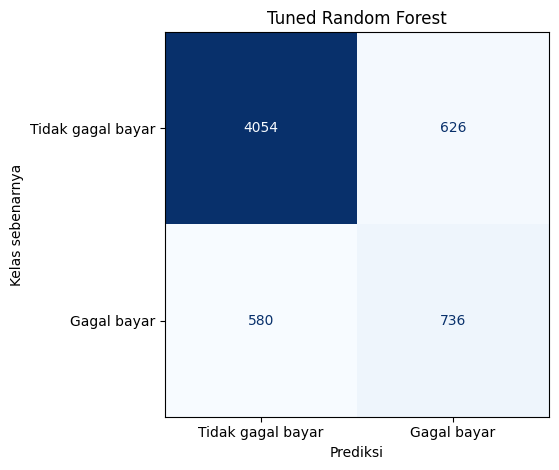

In [ ]:
prediksi_final = model_final.predict(X_test)
grafik = ConfusionMatrixDisplay.from_predictions(
    y_test, prediksi_final,
    labels=[0, 1],
    display_labels=['Tidak gagal bayar', 'Gagal bayar'],
    cmap='Blues', colorbar=False
)
grafik.ax_.set_xlabel('Prediksi')
grafik.ax_.set_ylabel('Kelas sebenarnya')
plt.title(nama_final)
plt.tight_layout()
plt.show()

Model Tuned Random Forest memprediksi dengan benar 4,054 nasabah yang tidak gagal bayar dan 736 nasabah yang mengalami gagal bayar. Sebanyak 626 nasabah yang tidak gagal bayar keliru diprediksi gagal bayar, sedangkan 580 kasus gagal bayar tidak terdeteksi.

Akurasi model sebesar 79.89% dan recall sebesar 55.93%. Recall menunjukkan proporsi kasus gagal bayar yang berhasil ditemukan, sementara kesalahan positif menunjukkan nasabah tanpa gagal bayar yang tetap ditandai oleh model.

# H. Analisis Hasil

1. Apakah preprocessing meningkatkan performa?

Preprocessing meningkatkan CV F1 Logistic Regression, dari 0.0004 menjadi 0.4646. Test F1 berubah dari 0.0000 menjadi 0.4768, dengan precision 0.6938 dan recall 0.3632 setelah preprocessing.

2. Model mana yang terbaik sebelum tuning?

Pada eksperimen 3, Random Forest memperoleh CV F1 tertinggi sebesar 0.4697. Random Forest memperoleh CV F1 0.4697 dan menjadi fokus tuning pada eksperimen 4 untuk mengevaluasi pengaruh pengaturan parameternya; model final tetap dipilih dengan membandingkan CV F1 seluruh kandidat.

3. Apakah tuning meningkatkan performa?

Tuning meningkatkan CV F1 Random Forest dari 0.4697 menjadi 0.5453, sedangkan Test F1 berubah dari 0.4693 menjadi 0.5497. Recall berubah dari 0.3663 menjadi 0.5593, dan precision dari 0.6531 menjadi 0.5404.

4. Apakah advanced model lebih baik?

HistGradientBoosting memperoleh CV F1 0.4701, sama atau lebih rendah dibandingkan tuned Random Forest dengan CV F1 0.5453. Test F1 keduanya masing-masing sebesar 0.4843 dan 0.5497; perbandingan ini berlaku untuk konfigurasi serta pembagian data yang diuji.

5. Model mana yang dipilih sebagai model final?

Model final adalah Tuned Random Forest, dengan CV F1 tertinggi sebesar 0.5453 dan Test F1 0.5497. Pemilihan didasarkan pada CV F1 untuk menilai keseimbangan precision dan recall pada kelas gagal bayar, sedangkan hasil testing memberikan evaluasi pada data yang tidak dipakai untuk melatih atau memilih parameter model.

# Kesimpulan

Berdasarkan seluruh eksperimen, Tuned Random Forest dipilih sebagai model final dengan CV F1 0.5453 dan Test F1 0.5497. Preprocessing meningkatkan CV F1 Logistic Regression, sedangkan tuning meningkatkan CV F1 Random Forest. Model final memperoleh precision 0.5404 dan recall 0.5593, sehingga keberhasilan menemukan kasus gagal bayar tetap perlu dipertimbangkan bersama jumlah prediksi gagal bayar yang keliru.

Kesimpulan ini didasarkan pada lima fold data training dan satu test set yang sama untuk seluruh model. CV F1 terbaik dari tuning dapat optimistis karena dipilih dari beberapa kombinasi parameter, sehingga tidak boleh dianggap sebagai jaminan performa pada populasi lain. Pengujian pada data lain masih diperlukan untuk menilai konsistensi model dan mendukung penerapannya lebih lanjut.